# Análisis Exploratorio de Datos para la Evaluación de Riesgos

## 1. Problema a resolver

Una empresa de seguros quiere ajustar sus primas según la criminalidad de cada país y el tipo de delito.
Esta empresa cuenta con la misma cuota de seguros para cada país en el que opera; sin embargo, sospecha que existen zonas donde la predisposición a contratar un seguro es mayor que en otras; así como zonas donde un tipo de delito puede ser más frecuente que otro. Para estudiar esta predisposición, la empresa quiere explorar el nivel de exposición a crimen de cada país. En función de los resultados obtenidos en este estudio, modificará el coste de sus servicios en cada país.

### 1.1. Jurisdicciones

Alemania (DE), Austria (AT), Bélgica (BE), Bulgaria (BG), Chequia (CZ), Chipre (CY), Croacia (HR), Dinamarca (DK), Eslovaquia (SK), Eslovenia (SI), España (ES), Estonia (EE), Finlandia (FI), Francia (FR), Grecia (EL), Hungría (HU), Irlanda (IE), Italia (IT), Letonia (LV), Lituania (LT), Luxemburgo (LU), Malta (MT), Países Bajos (NL), Polonia (PL), Portugal (PT), Rumanía (RO), Suecia (SE), Islandia (IS), Liechtenstein (LI), Noruega (NO), Suiza (CH), Inglaterra y Gales (UKC-L), Escocia (UKM), Irlanda del Norte (UKN), Albania (AL), Bosnia y Herzegovina (BA), Kosovo (XK), Macedonia del Norte (MK), Montenegro (ME), Serbia (RS) y Turquía (TR).

### 1.2. Categorías

Homicidio (ICCS0101), tentativa de homicidio (ICCS0102), agresión grave (ICCS020111), secuestro (ICCS020221), violencia sexual (ICCS0301), violación (ICCS03011), agresión sexual (ICCS03012), explotación sexual (ICCS0302), pornografía infantil (ICCS030221), robo con violencia o intimidación (ICCS0401), robo con fuerza en inmuebles (ICCS0501), robo en vivienda (ICCS05012), hurto (ICCS0502), hurto de vehículo de motor o sus piezas (ICCS05021), delitos relacionados con drogas controladas o precursores (ICCS0601), participación en un grupo delictivo organizado (ICCS09051), fraude (ICCS0701), corrupción (ICCS0703), soborno (ICCS07031), blanqueo de capitales (ICCS07041), ataques contra sistemas informáticos (ICCS0903), contaminación o degradación ambiental (ICCS1001), traslado o vertido de residuos (ICCS1002), comercio o posesión de especies protegidas de fauna y flora (ICCS1003) y agotamiento o degradación de recursos naturales (ICCS1004).

## 2. Datos

### 2.1. Colección de los datos

Eurostat es la Oficina Estadística de la Unión Europea desde la firma del Tratado de Maastricht en Países Bajos por los estados miembros.
Esta entidad collecciona los datos de Institutos de Estadística Nacionales u otras autoridades relevantes como la policía y departamentos de justicia de cada país miembro de la Unión Europea.
Su página web https://ec.europa.eu/eurostat/web/main/data/database dispone de conjuntos de datos detallados sobre múltiples tópicos como economía, ciudadanía, industria, agricultura, transporte, energía y ciencia para 41 jurisdicciones desde 2008 que disminuyen a 38 en 2019.

### 2.2. Descripción de los datos

Yo trabajaré con los datos de ciudadanía referentes a crimen y justicia criminal.
De acuerdo con la Clasificación Internacional de Delitos con Fines Estadísticos (ICCS), cada registro cuenta con un código que identifica el tipo de delito al que se refiere.
Es posible consultar a qué tipo hace alusión cada identificador en la página 175 del manual:
https://ec.europa.eu/eurostat/web/products-manuals-and-guidelines/-/KS-GQ-17-010?inheritRedirect=true
He construido en utils el diccionario 'ICCS_ES', cuyas claves son los códigos de la ICCS y cuyos valores son el tipo de crimen relativos a nuestro estudio.
También es posible encontrar 'PAISES', un diccionario para los códigos de países.

In [724]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

En la siguiente tabla, 'unit' hace referencia a la unidad de medida; mientras que 'geo' es el código del país.

In [725]:
df_raw = pd.read_csv("data/estat_crim_off_cat.tsv", sep="\t", engine="python")
df_raw.head(n=2) # número de delitos registrados por categoría de delito

,"freq,iccs,unit,geo\TIME_PERIOD",2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,"A,ICCS0101,NR,AL",88,82,118,124,125,107,98,54,71,52,51,58,52,61,44,35,41
1,"A,ICCS0101,NR,AT",58,51,61,80,88,63,43,42,49,61,73,74,54,59,65,75,78


In [726]:
df_off_cat.info()

<class 'pandas.DataFrame'>
RangeIndex: 1774 entries, 0 to 1773
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   freq,iccs,unit,geo\TIME_PERIOD  1774 non-null   str  
 1   2008                            1774 non-null   str  
 2   2009                            1774 non-null   str  
 3   2010                            1774 non-null   str  
 4   2011                            1774 non-null   str  
 5   2012                            1774 non-null   str  
 6   2013                            1774 non-null   str  
 7   2014                            1774 non-null   str  
 8   2015                            1774 non-null   str  
 9   2016                            1774 non-null   str  
 10  2017                            1774 non-null   str  
 11  2018                            1774 non-null   str  
 12  2019                            1774 non-null   str  
 13  2020          

Por tanto, contamos con 1774 filas y 21 columnas con elementos de tipo string que necesitamos modificar como sigue:

### 2.3. Limpieza de los datos

In [727]:
# Separamos las que Eurostat denomina "dimensiones" de la primera columna
dims = df_raw.iloc[:, 0].str.split(",", expand = True) # expand = True pone cada partición en una columna
dims.columns = ["freq", "iccs", "unit", "geo"] # renombra las columnas generadas

# Pasamos las columnas de los años de string '2008 ' a integer 2008
vals = df_raw.iloc[:, 1:].copy() # seleccionamos todas las filas y columnas menos la primera columna (la de las dimensiones)
vals.columns = [int(c.strip()) for c in vals.columns] # eliminamos espacios de los nombres de las columnas seleccionadas y transformamos formato del resultado de str a int

# Generamos una nueva tabla con las columnas de dims y una nueva columna de años obtenida de fundir con las filas las columnas de vals
df_long = (pd.concat([dims, vals], axis=1).melt(id_vars=["freq", "iccs", "unit", "geo"], var_name="anio", value_name="valor_txt"))
df_long["anio"] = df_long["anio"].astype(int) # cambia el formato de los años de string a integer

# Eurostat puede emplear banderas como 'p': provisional o 'b': ruptura de serie, tras los números
partes = df_long["valor_txt"].str.strip().str.extract(r"^([\d.]+|:)\s*([a-z]*)$") # separamos números y banderas en dos columnas
df_long["valor"] = pd.to_numeric(partes[0].replace(":", np.nan)) # Eurostat emplea ':' para datos no disponibles, que transformamos en Nan
df_long["bandera"] = partes[1].fillna("")

Los dos posibles valores para unit, `NR` (número de delitos) y `P_HTHAB` (delitos por cada 100.000 habitantes), se encuentran en la misma columna.
El siguiente paso clave será convertir cada valor de unit en una nueva columna, y dejar por índice el país, delito y año.

In [728]:
df = (df_long.dropna(subset=["valor"]) # se eliminan de la tabla los datos que hemos transformado a Nan por no estar disponibles
             .pivot_table(index=["geo", "iccs", "anio"], columns="unit", values="valor") # paso clave
             .reset_index() # Si una combinación solo tiene una de las dos unidades, la otra columna queda como NaN.
             .rename(columns={"NR": "n_delitos", "P_HTHAB": "tasa_100k"}))
df.columns.name = None # el nombre de las columnas que es 'unit' desaparece

Ahora, añadimos una columna que calcula la población total de cada país.

In [729]:
df["poblacion"] = np.where(df["tasa_100k"] > 0, df["n_delitos"] / df["tasa_100k"] * 1e5, np.nan) # evitamos dividir por 0

Por último, importamos los diccionarios de 'utils' y creamos las últimas columnas con sus valores.

In [730]:
import importlib, utils
importlib.reload(utils)

df["delito"] = df["iccs"].map(utils.ICCS_ES)
df["pais"] = df["geo"].map(utils.PAISES)
df["grupo"] = df["geo"].map(utils.grupo_pais)

### 2.4. Disponibilidad y calidad de los datos

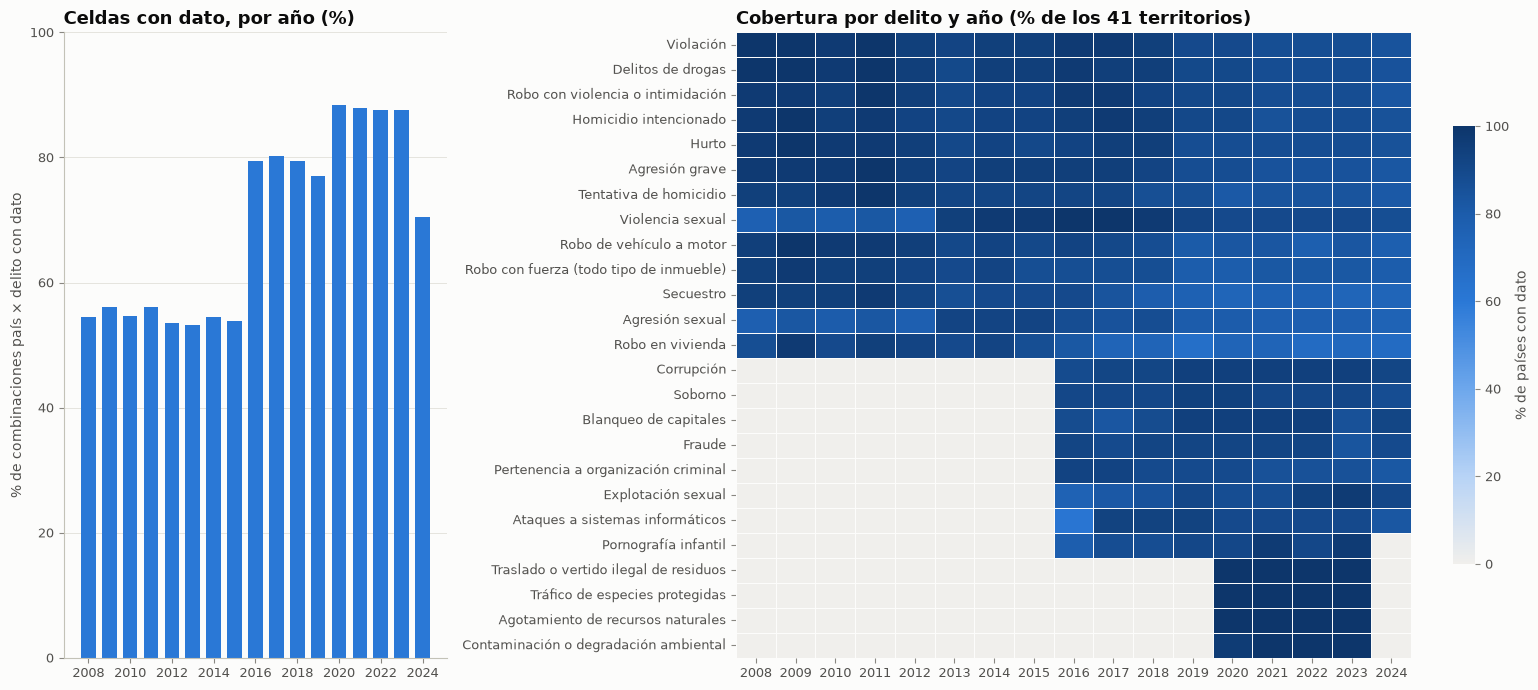

In [731]:
tasas_long = df_long[df_long["unit"] == "P_HTHAB"] # mascara para conseguir sólo las filas con el número de delitos por 100.000 habitantes
cobertura_anio = tasas_long.groupby("anio")["valor"].apply(lambda s: s.notna().mean() * 100)
cobertura_cat = (tasas_long.assign(hay=tasas_long["valor"].notna())
                           .groupby(["iccs", "anio"])["hay"].mean().mul(100).unstack())
cobertura_cat.index = cobertura_cat.index.map(utils.ICCS_ES)
cobertura_cat = cobertura_cat.loc[cobertura_cat.mean(axis=1).sort_values(ascending=False).index]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 2.2]})
ax = axes[0]
ax.bar(cobertura_anio.index, cobertura_anio.values, color=utils.AZUL, width=0.7)
ax.set_title("Celdas con dato, por año (%)")
ax.set_ylim(0, 100)
ax.set_xticks(cobertura_anio.index[::2])
ax.set_ylabel("% de combinaciones país × delito con dato")
ax.grid(axis="x", visible=False)

ax = axes[1]
sns.heatmap(cobertura_cat, cmap=utils.SECUENCIAL, vmin=0, vmax=100, ax=ax, linewidths=0.5, linecolor=utils.SUPERFICIE,
            cbar_kws={"label": "% de países con dato", "shrink": 0.7})
ax.set_title("Cobertura por delito y año (% de los 41 territorios)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [732]:
ultimo_anio = (df.groupby(["geo", "pais"])["anio"].agg(["min", "max"])
                 .rename(columns={"min": "primer_año", "max": "último_año"}))
ultimo_anio["delitos_con_dato_2021_24"] = (df[df["anio"].between(2021, 2024)]
                                           .groupby("geo")["iccs"].nunique()
                                           .reindex(ultimo_anio.index.get_level_values(0)).fillna(0).astype(int).values)
ultimo_anio.sort_values(["último_año", "delitos_con_dato_2021_24"]).head(10)

,,primer_año,último_año,delitos_con_dato_2021_24
geo,pais,,,
UKC-L,Inglaterra y Gales,2008,2018,0
UKM,Escocia,2008,2018,0
UKN,Irlanda del Norte,2008,2018,0
XK,Kosovo,2008,2021,12
TR,Turquía,2009,2024,7
IS,Islandia,2008,2024,16
LI,Liechtenstein,2008,2024,16
MK,Macedonia del Norte,2008,2024,17
IE,Irlanda,2008,2024,18


- Hasta **2015** solo hay datos en algo más de la mitad de las combinaciones país × delito
- En **2016** Eurostat añade los delitos económicos (fraude, corrupción, blanqueo, ciberataques, organización criminal)
- En **2020** los medioambientales, que de momento llegan a 2023.
- **2024 está incompleto**: faltan los medioambientales y algunos países aún no han enviado datos.

**Inglaterra y Gales, Escocia e Irlanda del Norte terminan en 2018** (salida del Reino Unido de la UE)

**Bosnia y Herzegovina en 2012** y **Kosovo en 2021**

**Turquía** solo informa de unos pocos delitos. Quedan fuera de la comparación reciente.

### 2.5. Análisis univariante

In [733]:
VENTANA = (2021, 2024)

nivel = (df[df["anio"].between(*VENTANA)]
         .groupby(["geo", "pais", "grupo", "iccs", "delito"], as_index=False)
         .agg(tasa=("tasa_100k", "mean"),
              n_total=("n_delitos", "sum"),
              anios=("tasa_100k", "count"),
              poblacion=("poblacion", "median")))

resumen_delitos = (nivel.groupby("delito")["tasa"]
                   .agg(paises="count", mediana="median", p25=lambda s: s.quantile(.25),
                        p75=lambda s: s.quantile(.75), minimo="min", maximo="max")
                   .sort_values("mediana", ascending=False))
resumen_delitos["max/min (sin ceros)"] = (nivel[nivel["tasa"] > 0].groupby("delito")["tasa"]
                                           .agg(lambda s: s.max() / s.min()))
resumen_delitos.round(1)

,paises,mediana,p25,p75,minimo,maximo,max/min (sin ceros)
delito,,,,,,,
Hurto,36,638.4,310.2,1307.9,55.2,2722.4,49.3
Fraude,34,257.7,89.8,675.5,12.9,2612.1,203.2
Robo con fuerza (todo tipo de inmueble),32,175.8,110.2,305.8,2.2,657.9,301.1
Delitos de drogas,35,126.9,58.9,428.9,27.7,1334.9,48.2
Robo en vivienda,29,76.9,48.1,171.2,16.2,385.6,23.9
Robo de vehículo a motor,35,35.7,17.3,86.5,4.1,411.6,100.5
Agresión grave,34,29.1,10.4,51.3,1.1,581.3,549.6
Violencia sexual,35,26.9,9.8,59.8,5.2,202.8,38.8
Robo con violencia o intimidación,36,19.1,12.0,36.0,3.1,127.4,40.7


In [734]:
estadisticos = (nivel.groupby("delito")["tasa"]
                .describe()
                .rename(columns={"count": "paises", "mean": "media", "std": "desv",
                                 "25%": "Q1", "50%": "mediana", "75%": "Q3"}))
estadisticos["rango"] = estadisticos["max"] - estadisticos["min"]
estadisticos["RIC"] = estadisticos["Q3"] - estadisticos["Q1"]
estadisticos.sort_values("mediana", ascending=False).round(1)

,paises,media,desv,min,Q1,mediana,Q3,max,rango,RIC
delito,,,,,,,,,,
Hurto,36.0,923.0,762.6,55.2,310.2,638.4,1307.9,2722.4,2667.2,997.7
Fraude,34.0,438.8,511.2,12.9,89.8,257.7,675.5,2612.1,2599.2,585.7
Robo con fuerza (todo tipo de inmueble),32.0,236.0,178.3,2.2,110.2,175.8,305.8,657.9,655.7,195.6
Delitos de drogas,35.0,273.7,303.6,27.7,58.9,126.9,428.9,1334.9,1307.2,370.0
Robo en vivienda,29.0,118.9,105.2,16.2,48.1,76.9,171.2,385.6,369.5,123.1
Robo de vehículo a motor,35.0,78.3,100.9,4.1,17.3,35.7,86.5,411.6,407.5,69.2
Agresión grave,34.0,72.7,135.8,1.1,10.4,29.1,51.3,581.3,580.2,40.9
Violencia sexual,35.0,44.8,48.4,5.2,9.8,26.9,59.8,202.8,197.6,50.0
Robo con violencia o intimidación,36.0,31.7,32.1,3.1,12.0,19.1,36.0,127.4,124.3,24.0


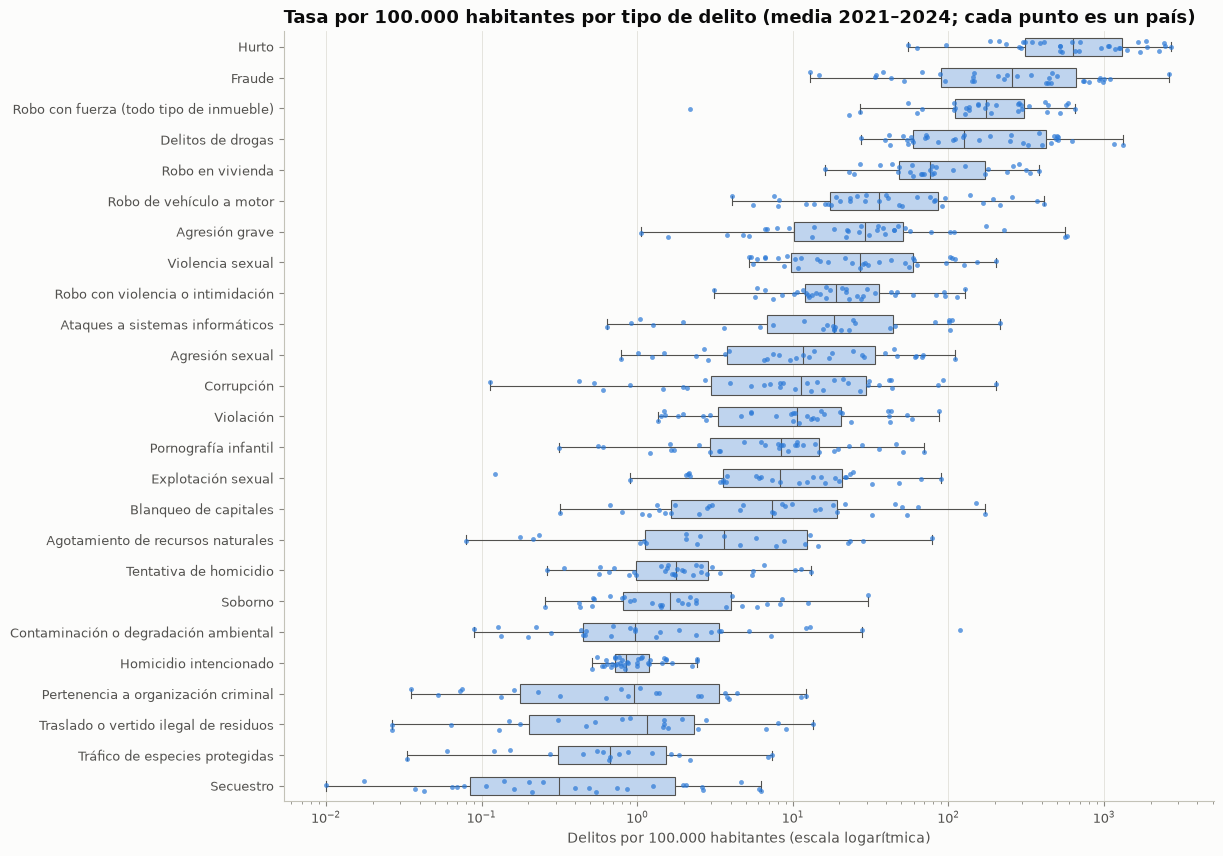

In [735]:
orden = resumen_delitos.index.tolist()
fig, ax = plt.subplots(figsize=(12, 10))
datos = nivel[nivel["tasa"] > 0]
sns.boxplot(data=datos, y="delito", x="tasa", order=orden, ax=ax, color="#b7d3f6",
            linecolor=utils.TINTA_2, linewidth=0.8, fliersize=0, width=0.6, log_scale=True)
sns.stripplot(data=datos, y="delito", x="tasa", order=orden, ax=ax, color=utils.AZUL, size=3.5, alpha=0.7, jitter=0.2)
ax.set_title("Tasa por 100.000 habitantes por tipo de delito (media 2021–2024; cada punto es un país)")
ax.set_xlabel("Delitos por 100.000 habitantes (escala logarítmica)")
ax.set_ylabel("")
plt.show()

- El **hurto** domina con diferencia (mediana de unos 640 por 100.000 habitantes), seguido del **fraude** (≈260) y del **robo con fuerza** (≈180).
- El homicidio (≈0,8) y el secuestro (≈0,2) son residuales en volumen, aunque muy caros por siniestro.
- La columna `max/min` es la clave para la aseguradora: en **homicidio** el país más alto multiplica por menos de 5 al más bajo, mientras que en **agresión grave** la distancia es de unas 550 veces y en **corrupción** de unas 1.800. Una diferencia así no es criminalidad real: refleja definiciones legales y formas de registrar distintas. El homicidio es el delito más comparable entre países; los delitos económicos y la agresión grave, los menos.
- En el gráfico no aparecen las tasas iguales a cero (no caben en escala logarítmica).

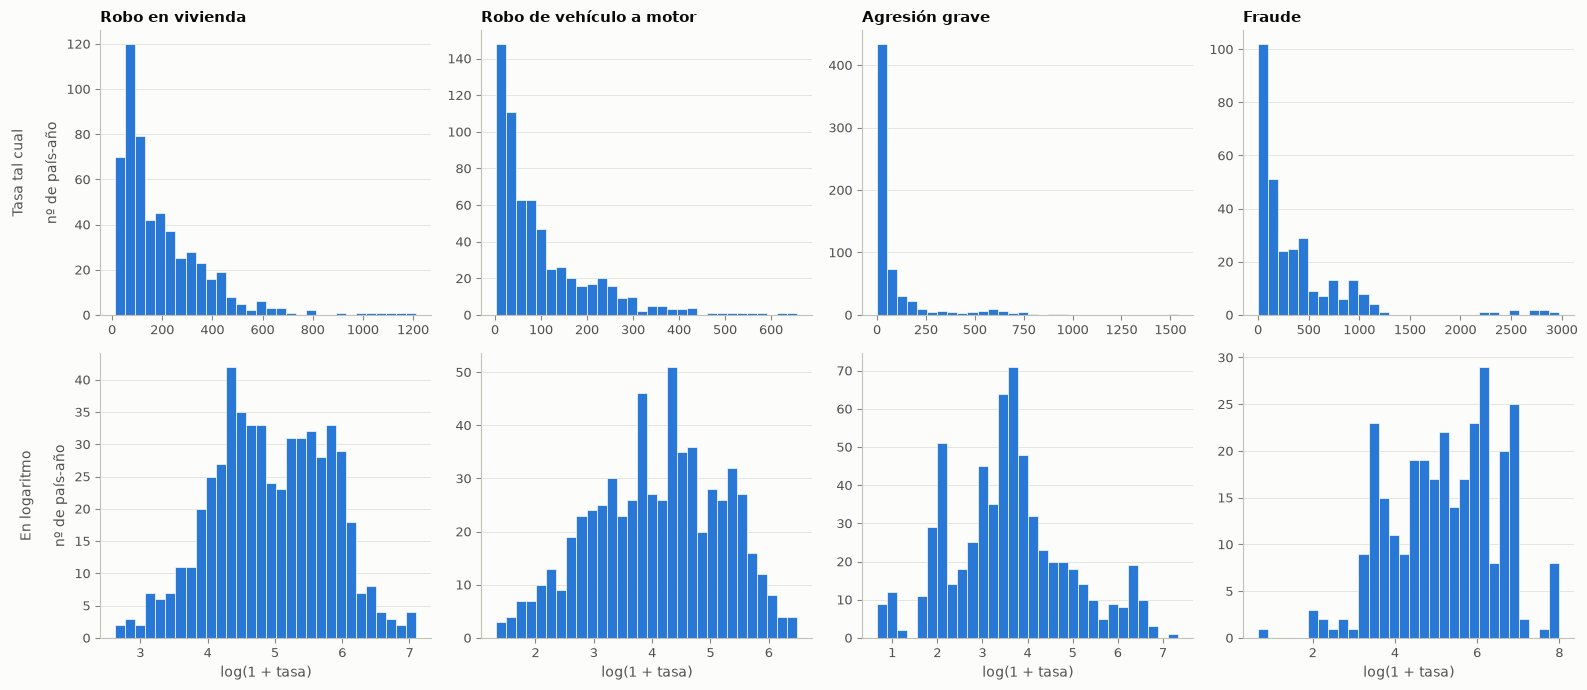

In [736]:
CLAVE = ["ICCS05012", "ICCS05021", "ICCS020111", "ICCS0701"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, cod in enumerate(CLAVE):
    s = df.loc[df["iccs"] == cod, "tasa_100k"].dropna()
    axes[0, j].hist(s, bins=30, color=utils.AZUL, edgecolor=utils.SUPERFICIE, linewidth=0.5)
    axes[0, j].set_title(utils.ICCS_ES[cod], fontsize=11)
    axes[1, j].hist(np.log1p(s), bins=30, color=utils.AZUL, edgecolor=utils.SUPERFICIE, linewidth=0.5)
    axes[0, j].grid(axis="x", visible=False)
    axes[1, j].grid(axis="x", visible=False)
    axes[1, j].set_xlabel("log(1 + tasa)")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Tasa tal cual\n\nnº de país-año")
axes[1, 0].set_ylabel("En logaritmo\n\nnº de país-año")
plt.tight_layout()
plt.show()

Test de Shapiro-Wilk (H0: la muestra es normal) sobre la media 2021-2024 por país

In [737]:
filas = []
from scipy import stats
for cod in utils.ICCS_ES:
    s = nivel.loc[nivel["iccs"] == cod, "tasa"].dropna()
    if len(s) >= 8:
        filas.append({"delito": utils.ICCS_ES[cod], "n": len(s),
                      "asimetría": stats.skew(s),
                      "p normal (tasa)": stats.shapiro(s).pvalue,
                      "p normal (log 1+tasa)": stats.shapiro(np.log1p(s)).pvalue})
normalidad = pd.DataFrame(filas).set_index("delito")
print("Delitos en los que se rechaza normalidad (p < 0.05):")
print("  tasa tal cual :", (normalidad["p normal (tasa)"] < 0.05).sum(), "de", len(normalidad))
print("  en logaritmo  :", (normalidad["p normal (log 1+tasa)"] < 0.05).sum(), "de", len(normalidad))
normalidad.sort_values("asimetría", ascending=False).round(3).head(10)

Delitos en los que se rechaza normalidad (p < 0.05):
  tasa tal cual : 25 de 25
  en logaritmo  : 9 de 25


,n,asimetría,p normal (tasa),p normal (log 1+tasa)
delito,,,,
Contaminación o degradación ambiental,30,4.70,0.0,0.00e+00
Soborno,30,3.45,0.0,8.00e-03
Corrupción,34,3.28,0.0,6.80e-01
Agotamiento de recursos naturales,26,3.21,0.0,8.80e-02
Agresión grave,34,3.08,0.0,7.00e-01
Blanqueo de capitales,33,2.76,0.0,5.10e-02
Fraude,34,2.41,0.0,2.43e-01
Tráfico de especies protegidas,21,2.32,0.0,2.00e-03
Explotación sexual,32,2.32,0.0,8.59e-01


Las tasas **no son normales** en ningún delito: todas tienen una cola larga a la derecha (unos pocos países con tasas muy altas).

En logaritmo la normalidad se rechaza en 9 de 25 delitos, así que se parecen más a una **log-normal**.

Consecuencias prácticas: comparo con la **mediana** y no con la media, uso escalas logarítmicas y combino delitos con medias geométricas (medias de logaritmos).

### 2.6. Análisis Multivariante

Para comparar delitos con escalas muy distintas (el hurto se mide en miles por 100.000 habitantes y el homicidio en unidades) uso la **relatividad**: la tasa del país dividida por la mediana de todos los países en ese delito. 1 = en la mediana, 2 = el doble, 0.5 = la mitad. En el mapa de calor uso escala log2 para que "el doble" y "la mitad" estén a la misma distancia del centro.

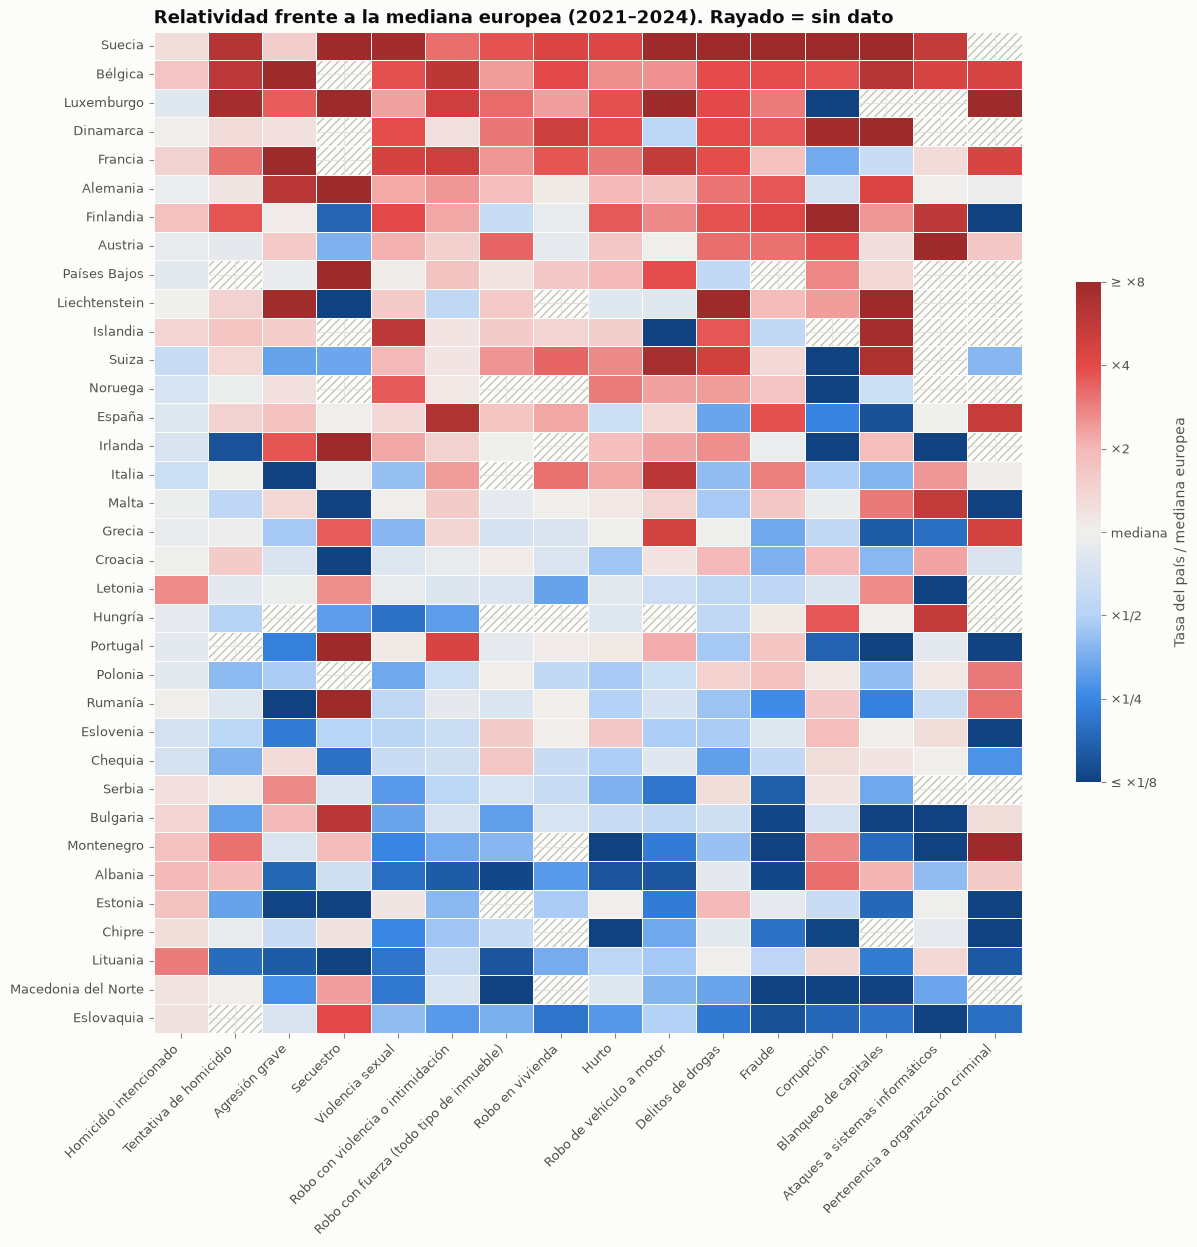

In [738]:
mediana_eur = nivel.groupby("iccs")["tasa"].median()
nivel["relatividad"] = nivel["tasa"] / nivel["iccs"].map(mediana_eur)

PRINCIPALES = ["ICCS0101", "ICCS0102", "ICCS020111", "ICCS020221", "ICCS0301", "ICCS0401",
               "ICCS0501", "ICCS05012", "ICCS0502", "ICCS05021", "ICCS0601", "ICCS0701",
               "ICCS0703", "ICCS07041", "ICCS0903", "ICCS09051"]

rel = (nivel[nivel["iccs"].isin(PRINCIPALES)]
       .pivot(index="pais", columns="iccs", values="relatividad")[PRINCIPALES])
rel = rel[rel.notna().mean(axis=1) >= 0.5]          # fuera países con menos de la mitad de delitos
rel_log2 = np.log2(rel.clip(lower=1/8, upper=8))
rel_log2 = rel_log2.loc[rel_log2.mean(axis=1).sort_values(ascending=False).index]
rel_log2.columns = [utils.ICCS_ES[c] for c in rel_log2.columns]

fig, ax = plt.subplots(figsize=(14, 13))
sns.heatmap(rel_log2, cmap=utils.DIVERGENTE, center=0, vmin=-3, vmax=3, ax=ax,
            linewidths=0.5, linecolor=utils.SUPERFICIE,
            cbar_kws={"label": "Tasa del país / mediana europea", "shrink": 0.5,
                      "ticks": [-3, -2, -1, 0, 1, 2, 3]})
cbar = ax.collections[0].colorbar
cbar.set_ticklabels(["≤ ×1/8", "×1/4", "×1/2", "mediana", "×2", "×4", "≥ ×8"])
ax.set_title("Relatividad frente a la mediana europea (2021–2024). Rayado = sin dato")
ax.set_xlabel("")
ax.set_ylabel("")
ax.patch.set_facecolor(utils.SUPERFICIE)
ax.patch.set_hatch("////")
ax.patch.set_edgecolor(utils.GRIS_CONTEXTO)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

- **Suecia, Bélgica, Luxemburgo, Dinamarca y Francia** están por encima de la mediana en casi todo. En el extremo contrario, los **Bálticos, los Balcanes y Europa central y del este** (Eslovaquia, Macedonia del Norte, Lituania, Chipre, Estonia, Albania…) registran mucho menos.
- Suecia es el caso conocido de cómo influyen las reglas de recuento: registra cada delito denunciado aunque luego no se confirme y tiene definiciones amplias (por ejemplo, de violencia sexual). Su posición dice tanto de su sistema estadístico como de su criminalidad.
- Hay casillas aisladas muy extremas (Bélgica y Francia en agresión grave, Italia muy baja en la misma categoría) que encajan mejor con diferencias de definición que con diferencias reales. Por eso el índice final recorta las relatividades.

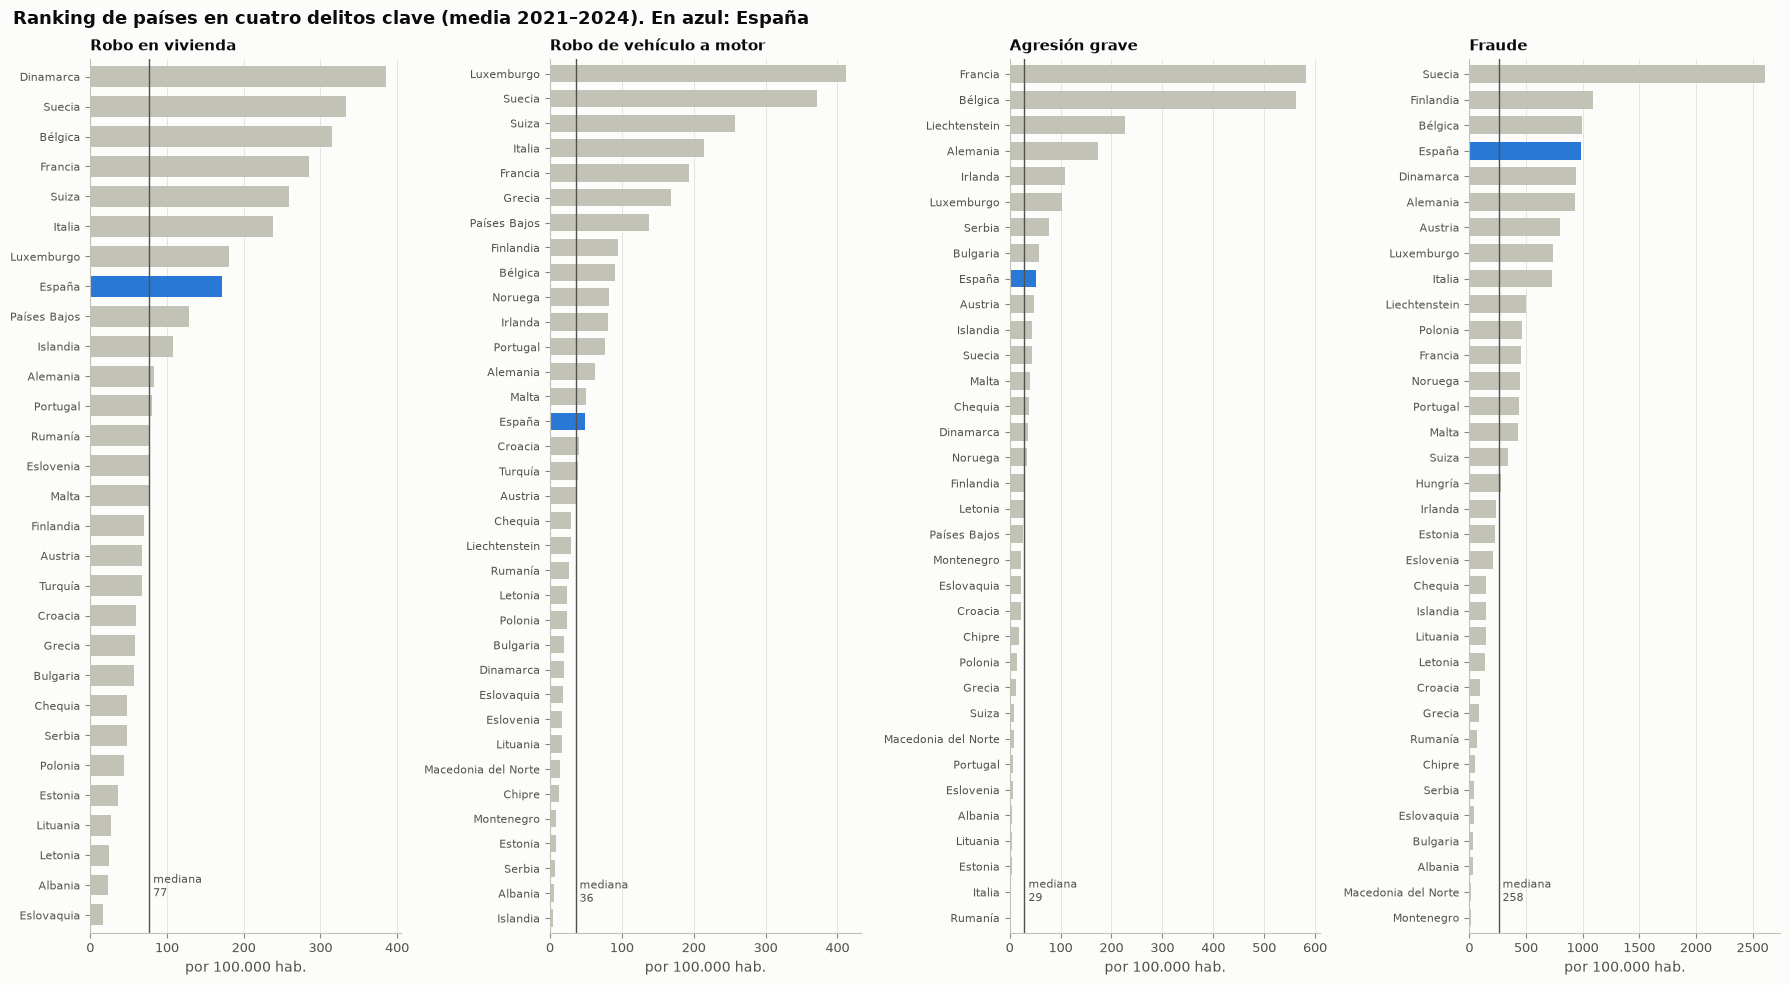

In [739]:
PAIS_REFERENCIA = "ES"   # país que se resalta en los gráficos

fig, axes = plt.subplots(1, 4, figsize=(18, 10), sharey=False)
for ax, cod in zip(axes, CLAVE):
    s = nivel[(nivel["iccs"] == cod) & nivel["tasa"].notna()].sort_values("tasa")
    colores = [utils.AZUL if g == PAIS_REFERENCIA else utils.GRIS_CONTEXTO for g in s["geo"]]
    ax.barh(s["pais"], s["tasa"], color=colores, height=0.7)
    ax.axvline(mediana_eur[cod], color=utils.TINTA_2, linewidth=1)
    ax.text(mediana_eur[cod], 0.5, f" mediana\n {mediana_eur[cod]:.0f}", color=utils.TINTA_2, fontsize=8, va="bottom")
    ax.set_ylim(-0.6, len(s) - 0.4)
    ax.set_title(utils.ICCS_ES[cod], fontsize=11)
    ax.set_xlabel("por 100.000 hab.")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle(f"Ranking de países en cuatro delitos clave (media 2021–2024). En azul: {utils.PAISES[PAIS_REFERENCIA]}",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

España está por encima de la mediana en robo en vivienda (≈2,2 veces), agresión grave (≈1,8) y sobre todo en fraude (≈3,8), y algo por encima en robo de vehículos (≈1,4). Lo más llamativo de España en el mapa de calor es el **robo con violencia o intimidación** (≈6,7 veces la mediana), que conviene contrastar con la definición nacional antes de usarlo para tarificar.

Correlación de Spearman (por rangos, robusta a los valores extremos) entre las tasas de los países. Si dos delitos están muy correlacionados, aportan información parecida al índice de un ramo.

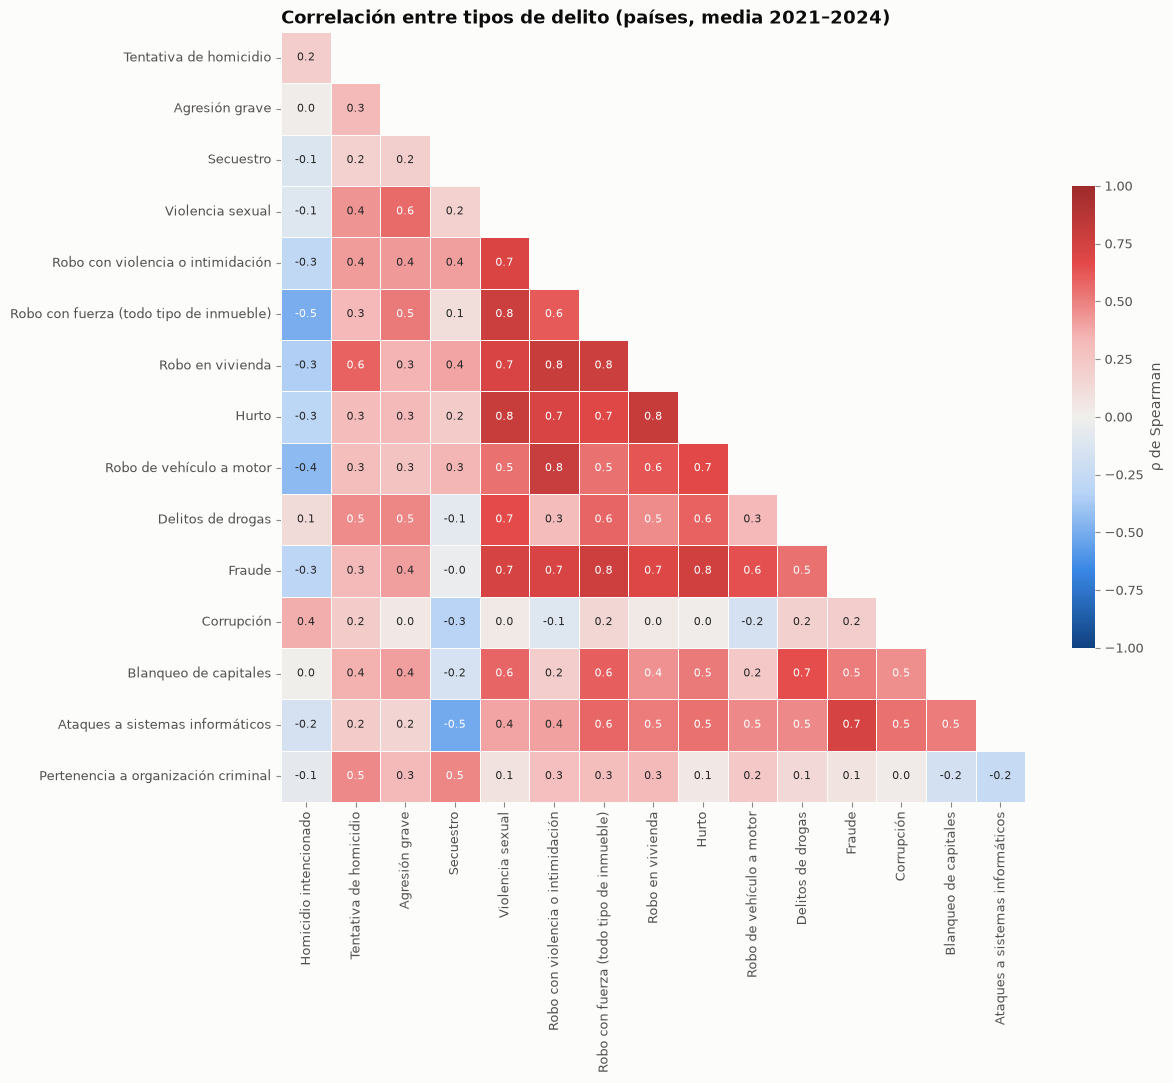

,delito A,delito B,rho
135,Hurto,Robo en vivienda,0.81
117,Robo en vivienda,Robo con violencia o intimidación,0.80
132,Hurto,Violencia sexual,0.80
149,Robo de vehículo a motor,Robo con violencia o intimidación,0.79
118,Robo en vivienda,Robo con fuerza (todo tipo de inmueble),0.78
100,Robo con fuerza (todo tipo de inmueble),Violencia sexual,0.78
182,Fraude,Robo con fuerza (todo tipo de inmueble),0.77
184,Fraude,Hurto,0.76


In [740]:
mat = nivel[nivel["iccs"].isin(PRINCIPALES)].pivot(index="geo", columns="iccs", values="tasa")[PRINCIPALES]
corr = mat.corr(method="spearman", min_periods=15)
corr.index = corr.columns = [utils.ICCS_ES[c] for c in corr.columns]

fig, ax = plt.subplots(figsize=(12, 10))
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr.iloc[1:, :-1], mask=mascara[1:, :-1], cmap=utils.DIVERGENTE, center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f",
            annot_kws={"fontsize": 8}, ax=ax, linewidths=0.5, linecolor=utils.SUPERFICIE,
            cbar_kws={"label": "ρ de Spearman", "shrink": 0.6})
ax.set_title("Correlación entre tipos de delito (países, media 2021–2024)")
ax.grid(False)
plt.show()

pares = (corr.where(~mascara).stack().rename("rho").reset_index()
             .rename(columns={"level_0": "delito A", "level_1": "delito B"}))
pares.reindex(pares["rho"].abs().sort_values(ascending=False).index).head(8).round(2)

- Los **delitos contra la propiedad van juntos**: hurto, robo en vivienda, robo con fuerza, robo con violencia, robo de vehículos y fraude tienen correlaciones de 0,5–0,8. Un país "caro" en hogar suele serlo también en automóvil y comercios.
- El **homicidio va en sentido contrario**: correlación negativa (−0,3 a −0,5) con casi todos los delitos contra la propiedad. Mi hipótesis: el homicidio se registra casi siempre, mientras que un hurto o un robo solo se registra si se denuncia, y se denuncia más donde hay más seguros (para cobrar hace falta la denuncia) y más confianza en la policía. Es decir, **parte de la criminalidad patrimonial registrada mide la propia penetración del seguro**. Para la aseguradora esto significa que una tasa baja en un país con poco seguro de hogar no implica necesariamente poco riesgo.

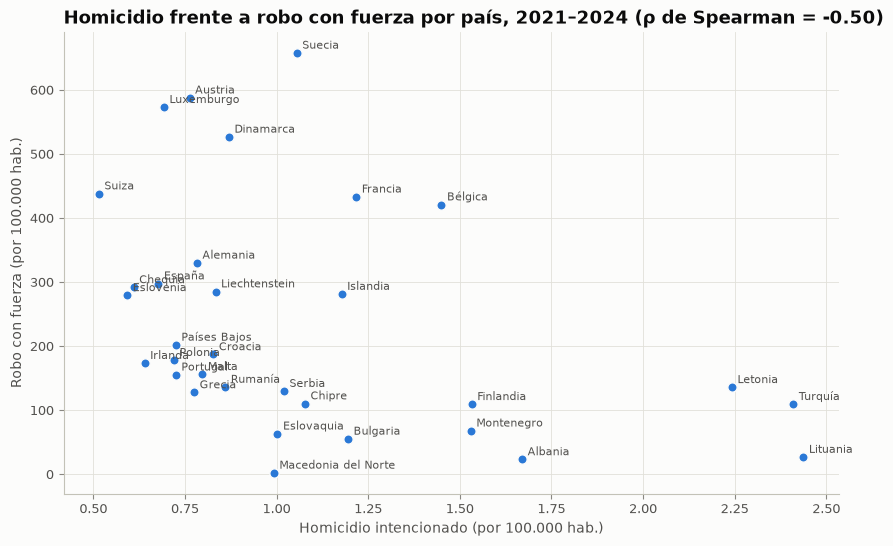

In [741]:
mat = nivel.pivot(index="pais", columns="iccs", values="tasa")
x, y = mat["ICCS0101"], mat["ICCS0501"]

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, color=utils.AZUL, s=45, edgecolor=utils.SUPERFICIE, linewidth=1)
for pais in mat.index[x.notna() & y.notna()]:
    ax.annotate(pais, (x[pais], y[pais]), xytext=(4, 3), textcoords="offset points", fontsize=8, color=utils.TINTA_2)
rho = stats.spearmanr(x, y, nan_policy="omit").statistic
ax.set_xlabel("Homicidio intencionado (por 100.000 hab.)")
ax.set_ylabel("Robo con fuerza (por 100.000 hab.)")
ax.set_title(f"Homicidio frente a robo con fuerza por país, 2021–2024 (ρ de Spearman = {rho:.2f})")
plt.show()

En un país de 40.000 habitantes un solo homicidio cambia la tasa por completo. Mido la volatilidad con el **coeficiente de variación** de la tasa anual (desviación típica / media, años 2008–2024) y la comparo con la población.

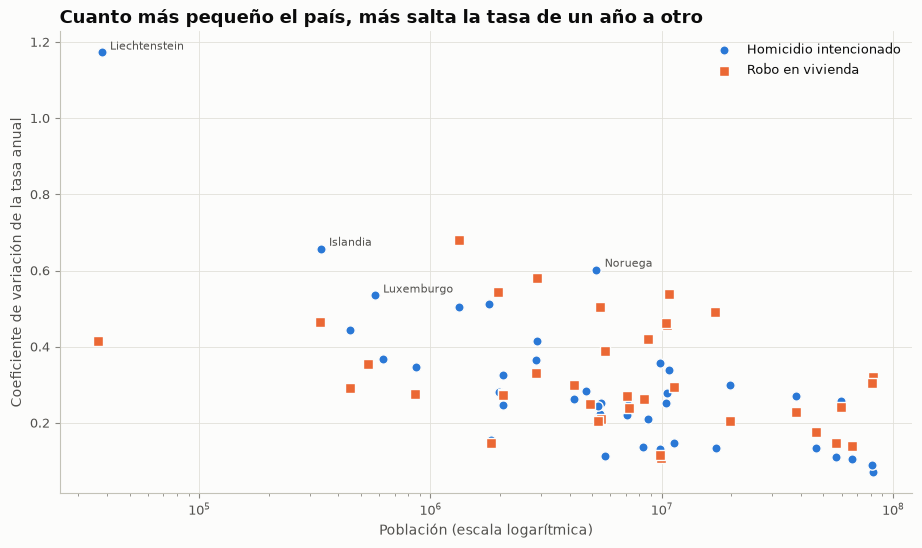

Correlación de Spearman población–volatilidad:
  Homicidio intencionado    rho = -0.72 (p = 0.000, n = 40)
  Robo en vivienda          rho = -0.32 (p = 0.056, n = 37)


In [742]:
def volatilidad(g):
    s = g["tasa_100k"].dropna()
    if len(s) < 6 or s.mean() == 0:
        return np.nan
    return s.std() / s.mean()

vol = (df[df["iccs"].isin(["ICCS0101", "ICCS05012"])]
       .groupby(["geo", "pais", "iccs"])
       .apply(lambda g: pd.Series({"volatilidad": volatilidad(g), "poblacion": g["poblacion"].median()}),
              include_groups=False)
       .reset_index().dropna())

fig, ax = plt.subplots(figsize=(11, 6))
for cod, color, marca in [("ICCS0101", utils.AZUL, "o"), ("ICCS05012", utils.NARANJA, "s")]:
    s = vol[vol["iccs"] == cod]
    ax.scatter(s["poblacion"], s["volatilidad"], color=color, marker=marca, s=45,
               edgecolor=utils.SUPERFICIE, linewidth=1, label=utils.ICCS_ES[cod])
for _, r in vol[(vol["iccs"] == "ICCS0101") & (vol["volatilidad"] > 0.52)].iterrows():
    ax.annotate(r["pais"], (r["poblacion"], r["volatilidad"]), xytext=(6, 2),
                textcoords="offset points", fontsize=8, color=TINTA_2)
ax.set_xscale("log")
ax.set_xlabel("Población (escala logarítmica)")
ax.set_ylabel("Coeficiente de variación de la tasa anual")
ax.set_title("Cuanto más pequeño el país, más salta la tasa de un año a otro")
ax.legend(loc="upper right")
plt.show()

print("Correlación de Spearman población–volatilidad:")
for cod in ["ICCS0101", "ICCS05012"]:
    s = vol[vol["iccs"] == cod]
    r = stats.spearmanr(s["poblacion"], s["volatilidad"])
    print(f"  {utils.ICCS_ES[cod]:<25} rho = {r.statistic:.2f} (p = {r.pvalue:.3f}, n = {len(s)})")

En homicidio la relación es clara (ρ ≈ −0,7): **Liechtenstein, Islandia o Luxemburgo** pasan de cero a varios casos por 100.000 habitantes de un año a otro. Noruega aparece alta porque la serie tiene un pico en 2011 (111 homicidios frente a unos 30 habituales), que coincide con los atentados de Oslo y Utøya: un solo suceso extremo mueve la serie entera. En robo en vivienda, con muchos más casos, la relación es más débil (ρ ≈ −0,3).

Esto justifica aplicar **credibilidad** en el índice: cuando un país registra pocos delitos de un tipo, su tasa es poco fiable y conviene acercarla a la mediana europea. Uso el criterio clásico de credibilidad de fluctuación limitada: plena credibilidad con 1.082 sucesos (90 % de probabilidad de estar a ±5 % de la frecuencia real) y, por debajo, `Z = √(n / 1.082)`.

Eurostat recomienda comparar **tendencias** más que niveles, porque dentro de un mismo país las definiciones cambian menos que entre países. Indexo la serie de cada país a 2016 = 100 (primer año con buena cobertura) y marco la mediana de todos los países.

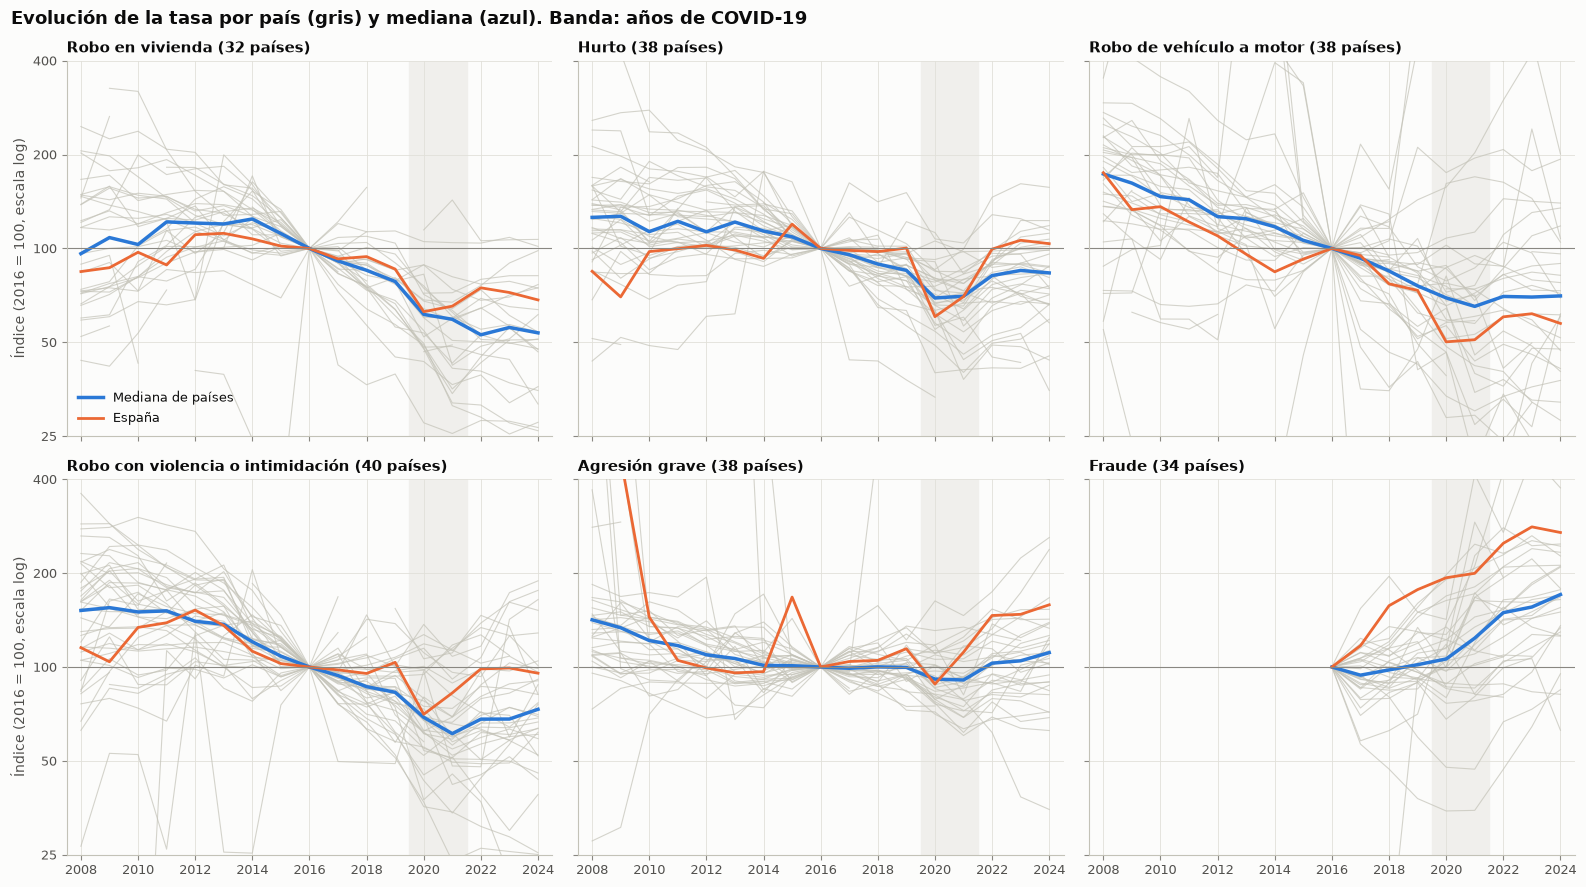

In [743]:
EVOL = ["ICCS05012", "ICCS0502", "ICCS05021", "ICCS0401", "ICCS020111", "ICCS0701"]
BASE = 2016

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True, sharex=True)
for ax, cod in zip(axes.flat, EVOL):
    p = df[df["iccs"] == cod].pivot(index="anio", columns="geo", values="tasa_100k")
    p = p.loc[:, p.loc[BASE].fillna(0) > 0]
    idx = p.div(p.loc[BASE]) * 100
    for g in idx.columns:
        ax.plot(idx.index, idx[g], color=utils.GRIS_CONTEXTO, linewidth=0.8, alpha=0.7)
    med = idx.median(axis=1)
    ax.plot(med.index, med.values, color=utils.AZUL, linewidth=2.5, label="Mediana de países")
    if PAIS_REFERENCIA in idx.columns:
        ax.plot(idx.index, idx[PAIS_REFERENCIA], color=utils.NARANJA, linewidth=2, label=utils.PAISES[PAIS_REFERENCIA])
    ax.axhline(100, color=utils.TINTA_SUAVE, linewidth=0.8)
    ax.axvspan(2019.5, 2021.5, color="#f0efec", zorder=0)
    ax.set_yscale("log")
    ax.set_ylim(25, 400)
    ax.yaxis.set_major_locator(mpl.ticker.FixedLocator([25, 50, 100, 200, 400]))
    ax.yaxis.set_major_formatter(mpl.ticker.FixedFormatter(["25", "50", "100", "200", "400"]))
    ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    ax.set_xlim(2007.5, 2024.5)
    ax.set_title(f"{utils.ICCS_ES[cod]} ({idx.shape[1]} países)", fontsize=11)
axes[0, 0].legend(loc="lower left")
axes[0, 0].set_ylabel(f"Índice ({BASE} = 100, escala log)")
axes[1, 0].set_ylabel(f"Índice ({BASE} = 100, escala log)")
fig.suptitle("Evolución de la tasa por país (gris) y mediana (azul). Banda: años de COVID-19",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [744]:
med_tabla = {}
for cod in EVOL + ["ICCS0101", "ICCS0903"]:
    p = df[df["iccs"] == cod].pivot(index="anio", columns="geo", values="tasa_100k")
    p = p.loc[:, (p.loc[BASE].fillna(0) > 0) & p.loc[2024].notna()]
    med_tabla[utils.ICCS_ES[cod]] = (p.loc[[2019, 2020, 2024]].div(p.loc[BASE]) * 100).median(axis=1)
evol_tabla = pd.DataFrame(med_tabla).T.round(0)
evol_tabla.columns = [f"índice {c}" for c in evol_tabla.columns]
evol_tabla.sort_values("índice 2024")

,índice 2019,índice 2020,índice 2024
Robo en vivienda,78.0,61.0,54.0
Robo de vehículo a motor,77.0,73.0,70.0
Robo con violencia o intimidación,83.0,69.0,73.0
Hurto,85.0,71.0,83.0
Homicidio intencionado,95.0,95.0,96.0
Agresión grave,100.0,91.0,111.0
Ataques a sistemas informáticos,115.0,113.0,158.0
Fraude,102.0,108.0,171.0


- **Los delitos contra la propiedad caen con fuerza**: en el país mediano, el robo en vivienda está en 2024 un 46 % por debajo de 2016, el robo de vehículos un 30 % y el robo con violencia un 27 %. El COVID-19 (2020–2021) aceleró la caída; después, el hurto es el que más ha rebotado.
- **El fraude (+71 %) y los ataques a sistemas informáticos (+58 %) suben** en casi todos los países. La delincuencia se está desplazando de la calle a internet.
- El homicidio está estable y la agresión grave sube ligeramente (+11 %).
- En España el fraude casi se ha triplicado desde 2016 (índice ≈270), muy por encima de la mediana.

**Tendencia por país.** Para cada país y delito estimo el cambio anual con la pendiente de Theil–Sen sobre el logaritmo de la tasa (2016–2024). Theil–Sen usa la mediana de las pendientes entre pares de años, así que un año raro (como 2020) o un salto puntual pesan poco.

In [745]:
PERIODO_TEND = (2016, 2024)

def tendencia(g):
    g = g[(g["anio"].between(*PERIODO_TEND)) & (g["tasa_100k"] > 0)]
    if len(g) < 5:
        return np.nan
    return stats.theilslopes(np.log(g["tasa_100k"]), g["anio"]).slope

tend = (df.groupby(["geo", "iccs"])[["anio", "tasa_100k"]].apply(tendencia)
          .rename("pendiente_log").reset_index().dropna())
tend["cambio_anual_%"] = np.expm1(tend["pendiente_log"]) * 100

tabla_tend = tend.pivot(index="geo", columns="iccs", values="cambio_anual_%")
resumen_tend = (tend.groupby("iccs")["cambio_anual_%"]
                .agg(paises="count", mediana="median",
                     pct_paises_que_suben=lambda s: (s > 0).mean() * 100))
resumen_tend.index = resumen_tend.index.map(utils.ICCS_ES)
resumen_tend.sort_values("mediana").round(1)

,paises,mediana,pct_paises_que_suben
iccs,,,
Robo en vivienda,28,-8.5,3.6
Robo con fuerza (todo tipo de inmueble),31,-6.7,6.5
Robo con violencia o intimidación,37,-5.1,24.3
Robo de vehículo a motor,34,-4.6,32.4
Hurto,36,-3.0,22.2
Soborno,31,-1.6,45.2
Homicidio intencionado,36,-1.1,30.6
Corrupción,34,-0.9,41.2
Delitos de drogas,36,0.1,52.8


La tabla confirma el patrón con la tendencia anual de cada país: el **robo en vivienda baja un 8,5 % al año** en el país mediano y solo sube en 1 de 28 países; en el otro extremo, **ciberataques (+14 %/año), blanqueo (+13 %) y fraude (+8 %) suben en más del 80 % de los países**. La violencia sexual también sube (+5,6 %/año, 83 % de los países), probablemente en parte por reformas legales y más denuncias.

In [746]:
# Tendencias extremas: candidatas a ruptura de serie (cambio de definición o de registro)
extremas = tend[tend["cambio_anual_%"].abs() > 20].copy()
extremas["pais"] = extremas["geo"].map(utils.PAISES)
extremas["delito"] = extremas["iccs"].map(utils.ICCS_ES)
print(f"{len(extremas)} de {len(tend)} series cambian más de un 20 % al año")
extremas.sort_values("cambio_anual_%", ascending=False)[["pais", "delito", "cambio_anual_%"]].head(10).round(1)

48 de 669 series cambian más de un 20 % al año


,pais,delito,cambio_anual_%
225,Dinamarca,Blanqueo de capitales,118.6
8,Albania,Pornografía infantil,68.9
424,Islandia,Pornografía infantil,61.8
600,Malta,Corrupción,50.5
393,Hungría,Blanqueo de capitales,46.9
192,Alemania,Pornografía infantil,44.4
144,Chipre,Agresión sexual,40.7
515,Luxemburgo,Fraude,39.9
368,Croacia,Blanqueo de capitales,37.8
191,Alemania,Explotación sexual,37.7


In [747]:
(df[(df["geo"] == "LU") & (df["iccs"] == "ICCS05021")]
 .set_index("anio")["tasa_100k"].rename("Luxemburgo - robo de vehículo (por 100.000 hab.)").to_frame().T)

anio,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Luxemburgo - robo de vehículo (por 100.000 hab.),71.1,84.9,83.26,89.09,70.88,425.48,407.51,53.65,42.0,48.76,48.67,262.59,281.58,284.85,371.86,427.66,562.01


48 de las 669 series (un 7 %) cambian más de un 20 % al año, sobre todo en delitos económicos y sexuales, donde un cambio legal o una sola gran investigación pueden mover mucho la cifra. Algunas son demasiado bruscas para ser reales. El caso más claro es **Luxemburgo en robo de vehículos**: pasa de unos 50 a más de 260 por 100.000 habitantes de 2018 a 2019 (y ya tuvo otro salto en 2013–2014), lo que apunta a un cambio en la forma de registrar. El tope de tendencia del índice (±10 %) limita el efecto de estos saltos, pero son las primeras series que habría que revisar con las banderas de Eurostat.

<h2>Índice de riesgo por ramo y factor orientativo de prima</h2>

Combino todo lo anterior en un indicador por país y ramo. Paso a paso, para cada delito:

1. **Nivel**: relatividad frente a la mediana europea, recortada a [¼, 4] para que una definición legal muy distinta no dispare el resultado.
2. **Credibilidad**: la relatividad (en log) se multiplica por `Z = min(1, √(n / 1.082))`, con `n` = delitos registrados en 2021–2024. Con pocos casos, el país se acerca a la mediana.
3. **Tendencia**: la pendiente anual se mezcla con la mediana europea de ese delito con el mismo `Z`.

Y para cada ramo:

4. Media ponderada (con los pesos de `RAMOS`) de los delitos disponibles; solo si hay datos de al menos el 50 % del peso del ramo.
5. **Factor de nivel** = índice^`ELASTICIDAD`. La elasticidad (0,25 por defecto) es baja a propósito: la siniestralidad no crece 1:1 con la criminalidad registrada y, como hemos visto, parte de las diferencias de nivel entre países son de definición o de registro. Debe calibrarse con datos de siniestros.
6. **Factor de tendencia** = tendencia anual proyectada `HORIZONTE` años (del último dato a la vigencia de la póliza), con tope ±10 %. Si un delito no tiene serie suficiente (los medioambientales empiezan en 2020), no se aplica tendencia.
7. **Factor final** = nivel × tendencia, acotado a [0,75, 1,35].

Todos estos números son **parámetros de negocio**: están juntos en la celda siguiente para poder cambiarlos.

In [748]:
N_PLENA_CREDIBILIDAD = 1082
TOPE_RELATIVIDAD = 4
ELASTICIDAD = 0.25
HORIZONTE = 2              # años entre el último dato (2024) y la vigencia de la póliza
TOPE_TENDENCIA = 0.10
FACTOR_MIN, FACTOR_MAX = 0.75, 1.35
COBERTURA_MINIMA = 0.5

base = (nivel.dropna(subset=["tasa"])
             .merge(tend[["geo", "iccs", "pendiente_log"]], on=["geo", "iccs"], how="left"))
base["z"] = np.minimum(1, np.sqrt(base["n_total"].fillna(0) / N_PLENA_CREDIBILIDAD))
base["log_rel"] = np.log(base["relatividad"].clip(1 / TOPE_RELATIVIDAD, TOPE_RELATIVIDAD))
base["log_rel_cred"] = base["z"] * base["log_rel"]
pend_mediana = tend.groupby("iccs")["pendiente_log"].median()
base["pend_mediana"] = base["iccs"].map(pend_mediana).fillna(0)   # sin serie -> sin tendencia
base["pend_cred"] = (base["z"] * base["pendiente_log"].fillna(base["pend_mediana"])
                     + (1 - base["z"]) * base["pend_mediana"])

filas = []
for ramo, pesos in utils.RAMOS.items():
    sub = base[base["iccs"].isin(pesos)].copy()
    sub["peso"] = sub["iccs"].map(pesos)
    peso_total = sum(pesos.values())
    for (geo, pais), g in sub.groupby(["geo", "pais"]):
        cobertura = g["peso"].sum() / peso_total
        if cobertura < COBERTURA_MINIMA:
            continue
        filas.append({"geo": geo, "pais": pais, "ramo": ramo, "cobertura": cobertura,
                      "z_medio": np.average(g["z"], weights=g["peso"]),
                      "log_indice": np.average(g["log_rel_cred"], weights=g["peso"]),
                      "pend": np.average(g["pend_cred"], weights=g["peso"])})
indice = pd.DataFrame(filas)
indice["indice_nivel"] = np.exp(indice["log_indice"])
indice["factor_nivel"] = indice["indice_nivel"] ** ELASTICIDAD
indice["tendencia_anual_%"] = np.expm1(indice["pend"]) * 100
indice["factor_tendencia"] = np.exp(indice["pend"] * HORIZONTE).clip(1 - TOPE_TENDENCIA, 1 + TOPE_TENDENCIA)
indice["factor_final"] = (indice["factor_nivel"] * indice["factor_tendencia"]).clip(FACTOR_MIN, FACTOR_MAX)

print(f"{indice['pais'].nunique()} países, {len(indice)} combinaciones país × ramo")
print(f"Combinaciones en el tope superior: {(indice['factor_final'] >= FACTOR_MAX).mean():.0%} | "
      f"en el inferior: {(indice['factor_final'] <= FACTOR_MIN).mean():.0%}")
(indice.groupby("ramo")
       .agg(paises=("geo", "count"), factor_min=("factor_final", "min"),
            factor_mediano=("factor_final", "median"), factor_max=("factor_final", "max"),
            tendencia_mediana_pct=("tendencia_anual_%", "median"), z_medio=("z_medio", "mean"))
       .loc[list(utils.RAMOS)].round(2))

36 países, 221 combinaciones país × ramo
Combinaciones en el tope superior: 9% | en el inferior: 7%


,paises,factor_min,factor_mediano,factor_max,tendencia_mediana_pct,z_medio
ramo,,,,,,
Hogar,29,0.75,0.91,1.35,-6.58,1.00
Automóvil,35,0.75,0.97,1.35,-4.63,0.90
Comercios y pymes,36,0.75,0.97,1.35,-2.16,0.95
Vida y accidentes,35,0.82,1.01,1.35,0.31,0.64
Ciberriesgo,27,0.80,1.09,1.35,12.75,0.89
Crimen financiero (D&O),34,0.79,1.13,1.35,5.41,0.71
RC medioambiental,25,0.93,1.08,1.29,0.00,0.52


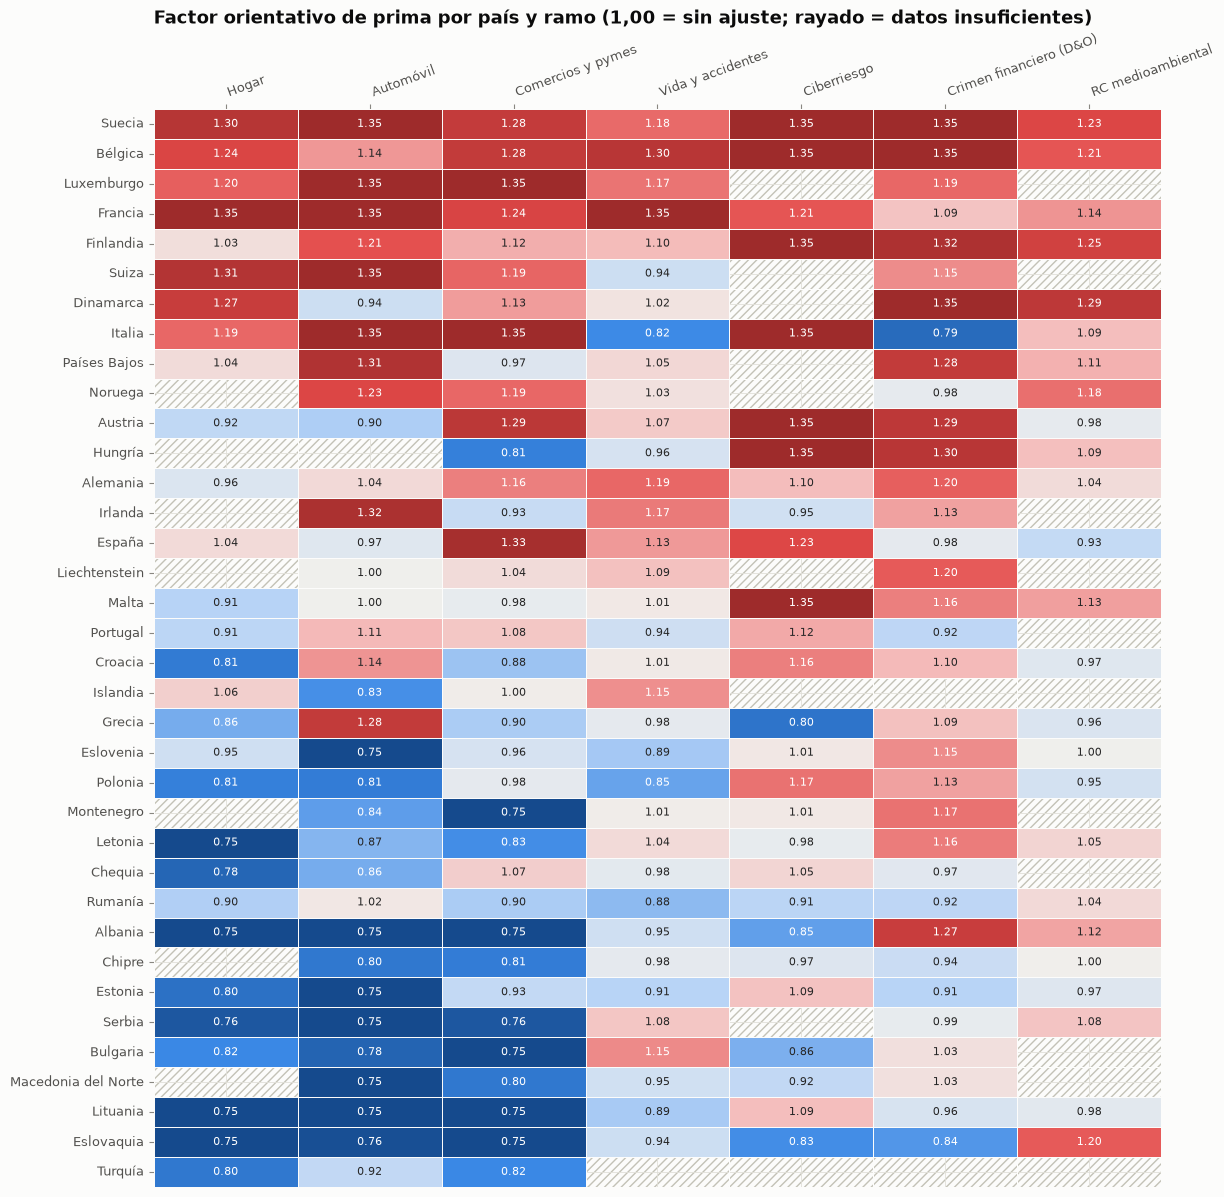

In [749]:
factores = indice.pivot(index="pais", columns="ramo", values="factor_final")[list(utils.RAMOS)]
factores = factores.loc[factores.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(13, 14))
sns.heatmap(np.log(factores), cmap=utils.DIVERGENTE, center=0, vmin=np.log(FACTOR_MIN), vmax=np.log(FACTOR_MAX),
            annot=factores, fmt=".2f", annot_kws={"fontsize": 8}, ax=ax,
            linewidths=0.5, linecolor=utils.SUPERFICIE, cbar=False)
ax.patch.set_facecolor(utils.SUPERFICIE)
ax.patch.set_hatch("////")
ax.patch.set_edgecolor(utils.GRIS_CONTEXTO)
ax.set_title("Factor orientativo de prima por país y ramo (1,00 = sin ajuste; rayado = datos insuficientes)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.xaxis.tick_top()
plt.setp(ax.get_xticklabels(), rotation=20, ha="left")
plt.show()

- Con estos parámetros, un 9 % de las combinaciones toca el techo (1,35) y un 7 % el suelo (0,75); el resto queda graduado.
- **Hogar** (mediana 0,91) y **Automóvil** (0,97) salen por debajo de 1 en el país mediano porque se proyecta la caída de los robos. **Ciberriesgo** (1,09) y **crimen financiero** (1,13) salen por encima por la tendencia al alza.
- **Vida y accidentes** y **RC medioambiental** tienen la credibilidad media más baja (Z ≈ 0,6 y 0,5): son delitos con pocos casos, así que sus factores se acercan a 1. En RC medioambiental, además, la serie empieza en 2020 y no aplico tendencia.
- Por países, el norte y el oeste (Suecia, Bélgica, Luxemburgo, Francia, Finlandia, Suiza) se concentran arriba, y el este y los Balcanes abajo, con la salvedad sobre la infradenuncia que vimos en las correlaciones.

In [750]:
# Desglose para el país de referencia: de dónde sale cada factor
detalle = (base[base["geo"] == PAIS_REFERENCIA]
           .assign(**{"cambio_anual_%": lambda d: np.expm1(d["pend_cred"]) * 100})
           [["iccs", "delito", "tasa", "relatividad", "z", "cambio_anual_%"]])
ramos_de = {c: ", ".join(r for r, p in utils.RAMOS.items() if c in p) for c in utils.ICCS_ES}
detalle["ramos"] = detalle["iccs"].map(ramos_de)
print(f"Detalle por delito — {utils.PAISES[PAIS_REFERENCIA]}")
display(detalle[detalle["ramos"] != ""].drop(columns="iccs").set_index("delito").round(2))
print(f"Factores por ramo — {utils.PAISES[PAIS_REFERENCIA]}")
(indice[indice["geo"] == PAIS_REFERENCIA]
 .set_index("ramo")[["cobertura", "indice_nivel", "factor_nivel", "tendencia_anual_%", "factor_tendencia", "factor_final"]]
 .round(3))

Detalle por delito — España


,tasa,relatividad,z,cambio_anual_%,ramos
delito,,,,,
Homicidio intencionado,0.68,0.80,1.00,1.28,Vida y accidentes
Tentativa de homicidio,2.58,1.45,1.00,7.28,Vida y accidentes
Agresión grave,52.60,1.81,1.00,6.07,Vida y accidentes
Secuestro,0.21,1.00,0.61,2.52,Vida y accidentes
Robo con violencia o intimidación,127.43,6.68,1.00,-0.29,Comercios y pymes
Robo con fuerza (todo tipo de inmueble),297.66,1.69,1.00,-1.07,Comercios y pymes
Robo en vivienda,171.16,2.23,1.00,-4.53,Hogar
Hurto,412.88,0.65,1.00,0.56,Hogar
Robo de vehículo a motor,48.41,1.36,1.00,-6.67,Automóvil


Factores por ramo — España


,cobertura,indice_nivel,factor_nivel,tendencia_anual_%,factor_tendencia,factor_final
ramo,,,,,,
Hogar,1.0,1.48,1.10,-2.86,0.94,1.04
Automóvil,1.0,1.36,1.08,-6.67,0.90,0.97
Comercios y pymes,1.0,2.57,1.27,2.48,1.05,1.33
Vida y accidentes,1.0,1.20,1.05,4.05,1.08,1.13
Ciberriesgo,1.0,1.56,1.12,13.51,1.10,1.23
Crimen financiero (D&O),1.0,0.63,0.89,7.89,1.10,0.98
RC medioambiental,1.0,0.74,0.93,0.00,1.00,0.93


En **España** destacan **Comercios y pymes (1,33)**, por el robo con violencia y el fraude, y **Ciberriesgo (1,23)**, por el fraude alto y creciente (+13 %/año). **Hogar (1,04)** y **Automóvil (0,97)** quedan casi neutros: el nivel está por encima de la mediana pero la tendencia a la baja lo compensa.